# Lab 3 – Variational Autoencoder on MNIST

In [1]:
%%writefile vae.py
import argparse
import json
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score
from torchvision import datasets


class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super(VAE, self).__init__()
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        # encoder outputs 2*D numbers: D means + D log-variances (log keeps sigma positive)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x.view(-1, 784))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        # reparameterization trick: z = mu + sigma * eps, so gradients flow into both mu and sigma
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z), mu, logvar


def vae_loss(recon, x, mu, logvar):
    mse = F.mse_loss(recon, x, reduction='sum')
    # KL(N(mu, sigma^2) || N(0, 1)), closed form, summed over latent dims
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (mse + kl) / x.shape[0], mse.item() / x.shape[0], kl.item() / x.shape[0]


class Classifier(nn.Module):
    def __init__(self):
        super(Classifier, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return self.fc2(F.relu(self.fc1(x.flatten(1))))


def batches(n, batch_size, shuffle=False):
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    return idx.split(batch_size)


def train_vae(vae, x_train, epochs, batch_size, lr):
    opt = optim.Adam(vae.parameters(), lr=lr)
    vae.train()
    for epoch in range(1, epochs + 1):
        total, total_mse, total_kl = 0, 0, 0
        for idx in batches(len(x_train), batch_size, shuffle=True):
            x = x_train[idx]
            recon, mu, logvar = vae(x)
            loss, mse, kl = vae_loss(recon, x, mu, logvar)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
            total_mse += mse * len(idx)
            total_kl += kl * len(idx)
        n = len(x_train)
        print('[VAE epoch %d/%d]: loss %.2f (mse %.2f, kl %.2f)' % (epoch, epochs, total / n, total_mse / n, total_kl / n))


@torch.no_grad()
def reconstruct(vae, x, batch_size=1000):
    # Decoder(Encoder(x)) with the sampling step, same as in training
    vae.eval()
    return torch.cat([vae(x[idx])[0] for idx in batches(len(x), batch_size)])


@torch.no_grad()
def encode_mu(vae, x, batch_size=1000):
    vae.eval()
    return torch.cat([vae.encode(x[idx])[0] for idx in batches(len(x), batch_size)])


def train_classifier(clf, x_train, y_train, epochs, batch_size, lr, name):
    opt = optim.Adam(clf.parameters(), lr=lr)
    clf.train()
    for epoch in range(1, epochs + 1):
        total = 0
        for idx in batches(len(x_train), batch_size, shuffle=True):
            loss = F.cross_entropy(clf(x_train[idx]), y_train[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        print('[%s classifier epoch %d/%d]: loss %.4f' % (name, epoch, epochs, total / len(x_train)))


@torch.no_grad()
def f1_scores(clf, x, y, batch_size=1000):
    # y is a numpy array of true labels; returns per-class F1 and their mean (macro F1)
    clf.eval()
    pred = torch.cat([clf(x[idx]).argmax(1) for idx in batches(len(x), batch_size)]).cpu().numpy()
    per_class = f1_score(y, pred, average=None, labels=range(10))
    return dict(macro_f1=float(per_class.mean()), per_class_f1=per_class.tolist())


def save_grid(rows, labels, path, n=10):
    fig, axes = plt.subplots(len(rows), n, figsize=(n, len(rows) * 1.1))
    for r, (imgs, label) in enumerate(zip(rows, labels)):
        for c in range(n):
            axes[r, c].imshow(imgs[c, 0].cpu(), cmap='gray', vmin=0, vmax=1)
            axes[r, c].axis('off')
        axes[r, 0].set_title(label, fontsize=9, loc='left')
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    plt.close(fig)


def plot_f1_bars(ax, series, title):
    # grouped bars: one group per digit, one bar per entry of series {label: per-class F1}
    width = 0.8 / len(series)
    for i, (label, per_class) in enumerate(series.items()):
        ax.bar(np.arange(10) - 0.4 + width * (i + 0.5), per_class, width, label=label)
    lowest = min(min(v) for v in series.values())
    ax.set_ylim(max(0, lowest - 0.05), 1)
    ax.set_xticks(range(10))
    ax.set_xlabel('digit')
    ax.set_ylabel('F1')
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)


if __name__ == '__main__':
    parser = argparse.ArgumentParser()
    parser.add_argument('--latent_dim', type=int, default=16)
    parser.add_argument('--vae_epochs', type=int, default=30)
    parser.add_argument('--clf_epochs', type=int, default=5)
    parser.add_argument('--batch_size', type=int, default=128)
    parser.add_argument('--lr', type=float, default=1e-3)
    parser.add_argument('--sigmas', type=float, nargs='+', default=[0.1, 0.2, 0.3])
    parser.add_argument('--tsne_points', type=int, default=2000)  # test images per t-SNE panel
    parser.add_argument('--seed', type=int, default=42)
    parser.add_argument('--out_dir', type=str, default='./results')
    args = parser.parse_args()

    device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
    torch.manual_seed(args.seed)
    os.makedirs(args.out_dir, exist_ok=True)

    # MNIST fits in memory, so keep it as plain tensors in [0, 1] on the device
    train_ds = datasets.MNIST(root='./mnist_data/', train=True, download=True)
    test_ds = datasets.MNIST(root='./mnist_data/', train=False, download=True)
    x_train = (train_ds.data.float() / 255).unsqueeze(1).to(device)
    y_train = train_ds.targets.to(device)
    x_test = (test_ds.data.float() / 255).unsqueeze(1).to(device)
    y_test = test_ds.targets.numpy()

    # ---------------- Part 1: train the VAE, original vs reconstructed ----------------
    vae = VAE(args.latent_dim).to(device)
    train_vae(vae, x_train, args.vae_epochs, args.batch_size, args.lr)
    torch.save(vae.state_dict(), f'{args.out_dir}/vae.pth')

    x_test_rec = reconstruct(vae, x_test)
    test_mse = F.mse_loss(x_test_rec, x_test).item()
    print('test per-pixel MSE: %.4f' % test_mse)
    save_grid([x_test[:10], x_test_rec[:10], x_test[10:20], x_test_rec[10:20]],
              ['original', 'reconstructed', 'original', 'reconstructed'], f'{args.out_dir}/part1_reconstructions.png')

    # latent interpolation: walk in a straight line between the mean codes of two classes and decode
    mu_test = encode_mu(vae, x_test)
    centers = torch.stack([mu_test[torch.from_numpy(y_test == c).to(device)].mean(0) for c in range(10)])
    pairs = [(1, 7), (4, 9), (3, 8), (1, 8), (0, 6)]
    t = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    with torch.no_grad():
        paths = [vae.decode((1 - t) * centers[a] + t * centers[b]) for a, b in pairs]
    save_grid(paths, [f'{a} -> {b}' for a, b in pairs], f'{args.out_dir}/part1_interpolation.png')

    # ---------------- Part 2: baseline vs reconstructed-data classifier ----------------
    x_train_rec = reconstruct(vae, x_train)

    clf_base = Classifier().to(device)
    train_classifier(clf_base, x_train, y_train, args.clf_epochs, args.batch_size, args.lr, 'baseline')
    clf_rec = Classifier().to(device)
    train_classifier(clf_rec, x_train_rec, y_train, args.clf_epochs, args.batch_size, args.lr, 'reconstructed')
    classifiers = [('baseline', clf_base), ('reconstructed', clf_rec)]

    results = dict(args=vars(args), test_mse=test_mse, part2={}, part3=[])
    results['part2'] = {name: f1_scores(clf, x_test, y_test) for name, clf in classifiers}
    print('Part 2 (clean original test set) macro F1: ' +
          ', '.join('%s %.4f' % (name, r['macro_f1']) for name, r in results['part2'].items()))

    fig, ax = plt.subplots(figsize=(8, 4))
    plot_f1_bars(ax, {name: r['per_class_f1'] for name, r in results['part2'].items()},
                 'Per-class F1 on the clean original test set')
    ax.legend()
    plt.tight_layout()
    plt.savefig(f'{args.out_dir}/part2_f1.png', dpi=120)
    plt.close(fig)

    # ---------------- Part 3: noisy test set, with and without VAE denoising ----------------
    noisy_rows, noisy_labels = [x_test[:10]], ['original']
    noisy_sets = {}
    for sigma in args.sigmas:
        x_noisy = (x_test + sigma * torch.randn_like(x_test)).clamp(0, 1)
        x_denoised = reconstruct(vae, x_noisy)
        noisy_sets[sigma] = x_noisy
        row = dict(sigma=sigma)
        for name, clf in classifiers:
            row[f'{name}_noisy'] = f1_scores(clf, x_noisy, y_test)
            row[f'{name}_denoised'] = f1_scores(clf, x_denoised, y_test)
        results['part3'].append(row)
        print('Part 3 sigma %.1f macro F1: ' % sigma +
              ', '.join('%s %.4f' % (k, v['macro_f1']) for k, v in row.items() if k != 'sigma'))
        noisy_rows += [x_noisy[:10], x_denoised[:10]]
        noisy_labels += [f'noisy sigma={sigma}', f'VAE-denoised sigma={sigma}']

    save_grid(noisy_rows, noisy_labels, f'{args.out_dir}/part3_denoising.png')

    fig, ax = plt.subplots(figsize=(6, 4))
    for name, color in [('baseline', 'tab:blue'), ('reconstructed', 'tab:orange')]:
        ax.plot(args.sigmas, [r[f'{name}_noisy']['macro_f1'] for r in results['part3']], '--o', color=color,
                label=f'{name} clf, noisy')
        ax.plot(args.sigmas, [r[f'{name}_denoised']['macro_f1'] for r in results['part3']], '-o', color=color,
                label=f'{name} clf, VAE-denoised')
    ax.set_xlabel('noise sigma')
    ax.set_ylabel('macro F1')
    ax.set_xticks(args.sigmas)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(f'{args.out_dir}/part3_macro_f1.png', dpi=120)
    plt.close(fig)

    fig, axes = plt.subplots(len(args.sigmas), 1, figsize=(9, 3.5 * len(args.sigmas)))
    for ax, row in zip(np.atleast_1d(axes), results['part3']):
        plot_f1_bars(ax, {k.replace('_', ', '): v['per_class_f1'] for k, v in row.items() if k != 'sigma'},
                     f'Per-class F1, noise sigma={row["sigma"]}')
    np.atleast_1d(axes)[0].legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig(f'{args.out_dir}/part3_f1_per_class.png', dpi=120)
    plt.close(fig)

    # ---------------- Latent space: t-SNE of mu, clean and noisy test images in one embedding ----------------
    # one joint t-SNE so all panels share the same 2D map and noisy codes can be compared with clean ones
    n = args.tsne_points
    sets = [('clean', x_test[:n])] + [(f'noisy sigma={s}', noisy_sets[s][:n]) for s in args.sigmas]
    mu_all = torch.cat([encode_mu(vae, x) for _, x in sets]).cpu().numpy()
    emb = TSNE(n_components=2, init='pca', random_state=args.seed).fit_transform(mu_all).reshape(len(sets), n, 2)

    fig, axes = plt.subplots(1, len(sets), figsize=(4.5 * len(sets), 4.5))
    for i, (ax, (label, _)) in enumerate(zip(axes, sets)):
        if i > 0:
            ax.scatter(emb[0, :, 0], emb[0, :, 1], s=2, c='lightgrey')
        points = ax.scatter(emb[i, :, 0], emb[i, :, 1], s=2, c=y_test[:n], cmap='tab10', vmin=-0.5, vmax=9.5)
        ax.set_title(label)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.colorbar(points, ax=axes, ticks=range(10), label='true digit')
    plt.savefig(f'{args.out_dir}/latent_tsne.png', dpi=120)
    plt.close(fig)

    with open(f'{args.out_dir}/results.json', 'w') as f:
        json.dump(results, f, indent=2)

Writing vae.py


## Run

| param | default | meaning |
|---|---|---|
| `latent_dim` | 16 | size of the latent space D |
| `vae_epochs` | 30 | VAE training epochs |
| `clf_epochs` | 5 | epochs for each classifier |
| `batch_size` | 128 | |
| `lr` | 1e-3 | Adam, VAE and classifiers |
| `sigmas` | 0.1 0.2 0.3 | noise levels for Part 3 |
| `tsne_points` | 2000 | test images per t-SNE panel |

In [2]:
!python -u vae.py --out_dir results

100%|██████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 5.52MB/s]
100%|███████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 144kB/s]
100%|██████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 1.04MB/s]
100%|██████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 14.6MB/s]
[VAE epoch 1/30]: loss 48.03 (mse 44.78, kl 3.25)
[VAE epoch 2/30]: loss 35.07 (mse 27.61, kl 7.46)
[VAE epoch 3/30]: loss 32.57 (mse 24.08, kl 8.49)
[VAE epoch 4/30]: loss 31.33 (mse 22.26, kl 9.07)
[VAE epoch 5/30]: loss 30.57 (mse 21.11, kl 9.46)
[VAE epoch 6/30]: loss 29.99 (mse 20.26, kl 9.73)
[VAE epoch 7/30]: loss 29.59 (mse 19.65, kl 9.95)
[VAE epoch 8/30]: loss 29.25 (mse 19.16, kl 10.08)
[VAE epoch 9/30]: loss 28.98 (mse 18.77, kl 10.21)
[VAE epoch 10/30]: loss 28.78 (mse 18.47, kl 10.31)
[VAE epoch 11/30]: loss 28.57 (mse 18.20, kl 10.37)
[VAE epoch 12/30]: loss 28.42 (mse 17.96, kl 10.47)
[VAE epoch 13/30]: loss 28.25 (mse 17.73, kl 10.52)
[VAE epoch 14/30

In [3]:
import json
import pandas as pd
from IPython.display import Image, display

results = json.load(open('results/results.json'))

## Part 1 – original vs reconstructed

test per-pixel MSE: 0.0209


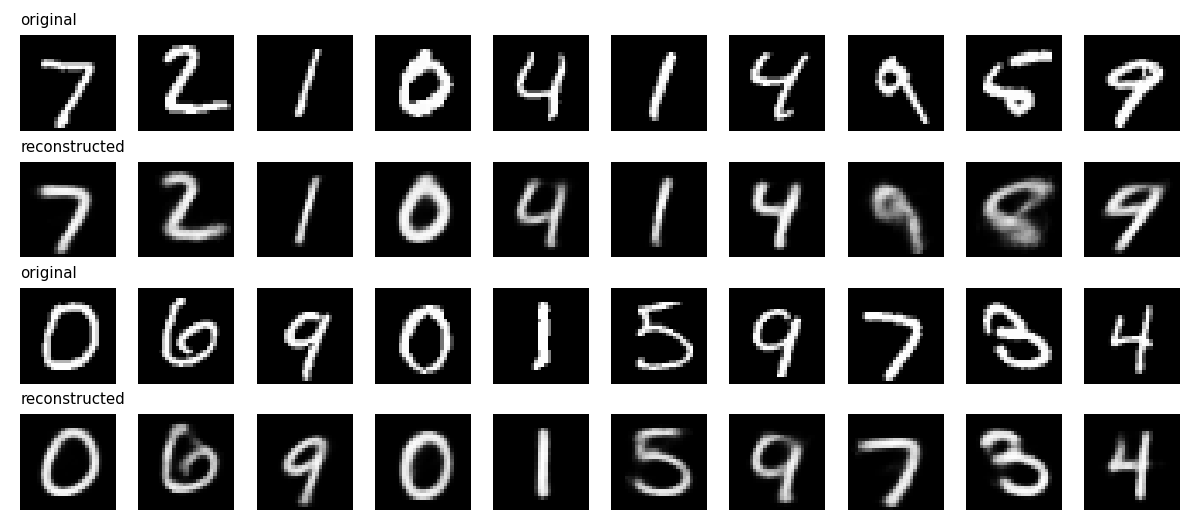

In [4]:
print('test per-pixel MSE: %.4f' % results['test_mse'])
display(Image('results/part1_reconstructions.png'))

**What survives / what gets lost** – compare the rows above:

- *Survives*: digit identity, position and overall shape – the 7, the 2, the 1s, the 0s and the 4s come back clearly.
- *Lost / blurred*: - edges become blurred, visible a lot on the 9s, the 8s, the 6s and the 2s
- Unusual digits are pulled towards a *typical* shape, sometimes of the wrong class: the odd "5" with a detached top bar (row 1, 9th) comes back as a blurry 8-like shape.

Why: a 16-dim latent with a KL pull towards N(0, 1) cannot store per-pixel detail, and the MSE optimum under uncertainty is the average of the plausible images, i.e. a blurry one.

### Latent interpolation between class centers

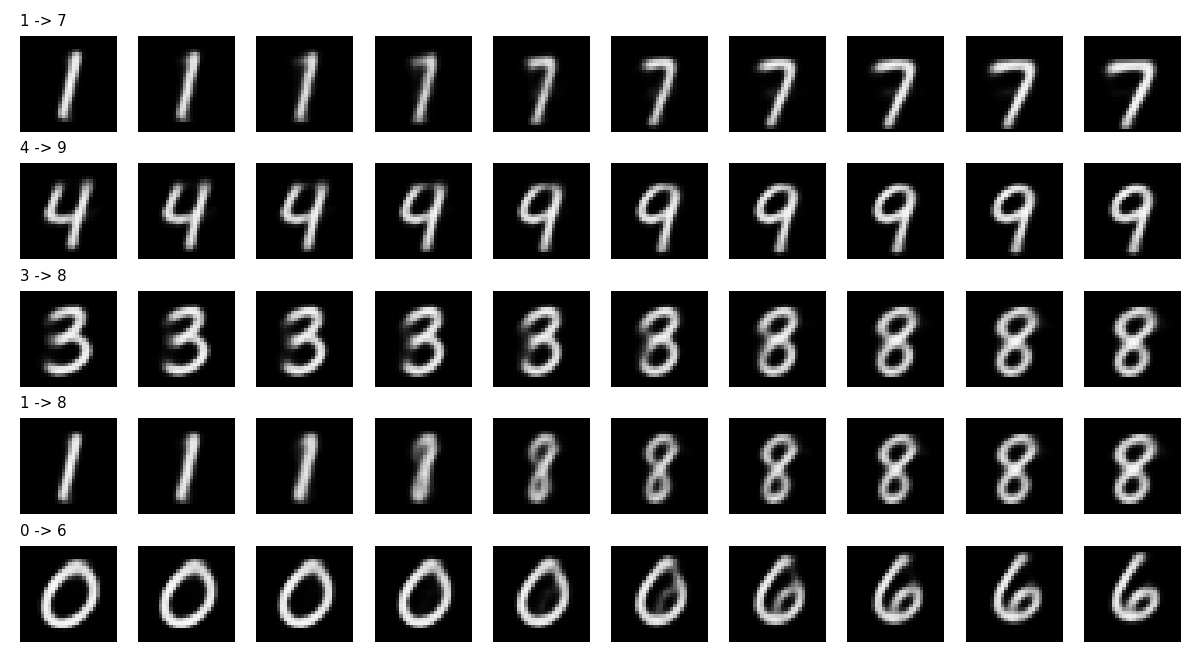

In [5]:
display(Image('results/part1_interpolation.png'))

Each row starts at the mean μ of one class, ends at the mean μ of another and decodes 10 evenly spaced points on the straight line between them.            
Every intermediate point decodes to a digit-like image that morphs gradually – there are no garbage frames in between. That is the smooth, hole-free latent space the KL term buys.

## Part 2 – baseline vs reconstructed classifier (clean original test set)

,baseline,reconstructed
F1 digit 0,0.9944,0.9736
F1 digit 1,0.9965,0.9821
F1 digit 2,0.9898,0.9599
F1 digit 3,0.9825,0.9640
F1 digit 4,0.9923,0.9709
F1 digit 5,0.9860,0.9666
F1 digit 6,0.9890,0.9740
F1 digit 7,0.9883,0.9642
F1 digit 8,0.9856,0.9414
F1 digit 9,0.9857,0.9456


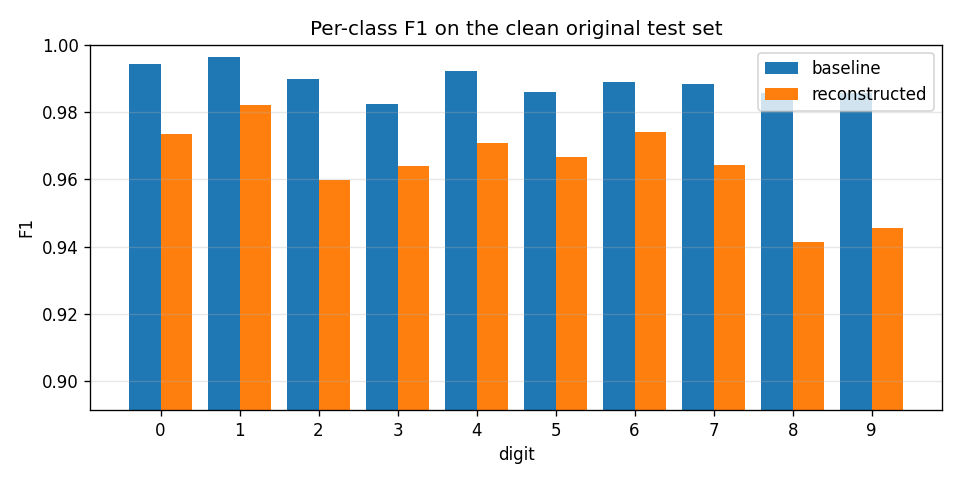

In [6]:
display(pd.DataFrame({name: r['per_class_f1'] + [r['macro_f1']] for name, r in results['part2'].items()},
                     index=[f'F1 digit {d}' for d in range(10)] + ['macro F1']).round(4))
display(Image('results/part2_f1.png'))

The reconstructed classifier only ever saw smooth, "averaged" digits, so the gap to the baseline measures how much classification-relevant detail the VAE throws away (plus a train/test shift: blurry train images vs sharp test images).

Some reconstructions look like a *different* digit than their label, so part of the reconstructed classifier training set is effectively mislabelled and cannot be fitted.
Macro F1 drops from 0.989 to 0.964. Per class, the gap is smallest for **1** (0.997 → 0.982) and largest for **8** (0.986 → 0.941) and **9** (0.986 → 0.946), then 2.
A single straight stroke survives blurring; 8 and 9 differ from their neighbours (3/5, 4/7) by small loops and gaps – exactly the fine detail the VAE smooths away. The t-SNE below shows the same: the 3/5/8 and 4/7/9 clusters touch.

## Part 3 – denoising

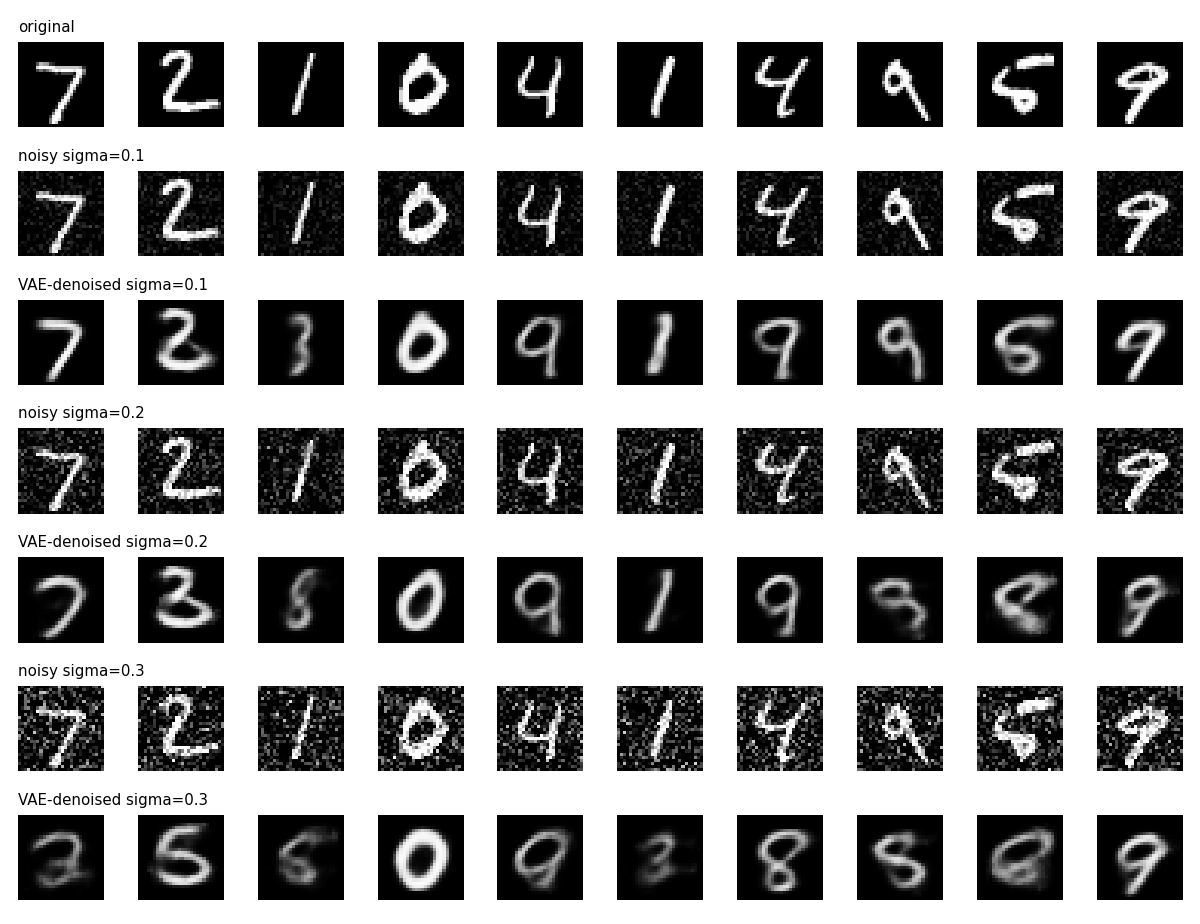

classifier baseline          reconstructed         
input         noisy denoised         noisy denoised
sigma                                              
0.1          0.9886   0.7844        0.9652   0.7934
0.2          0.9844   0.5216        0.9593   0.5251
0.3          0.9554   0.3739        0.9264   0.3722

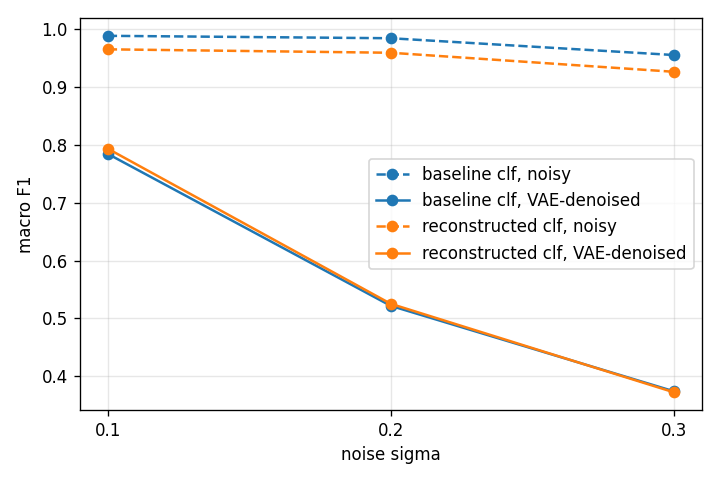

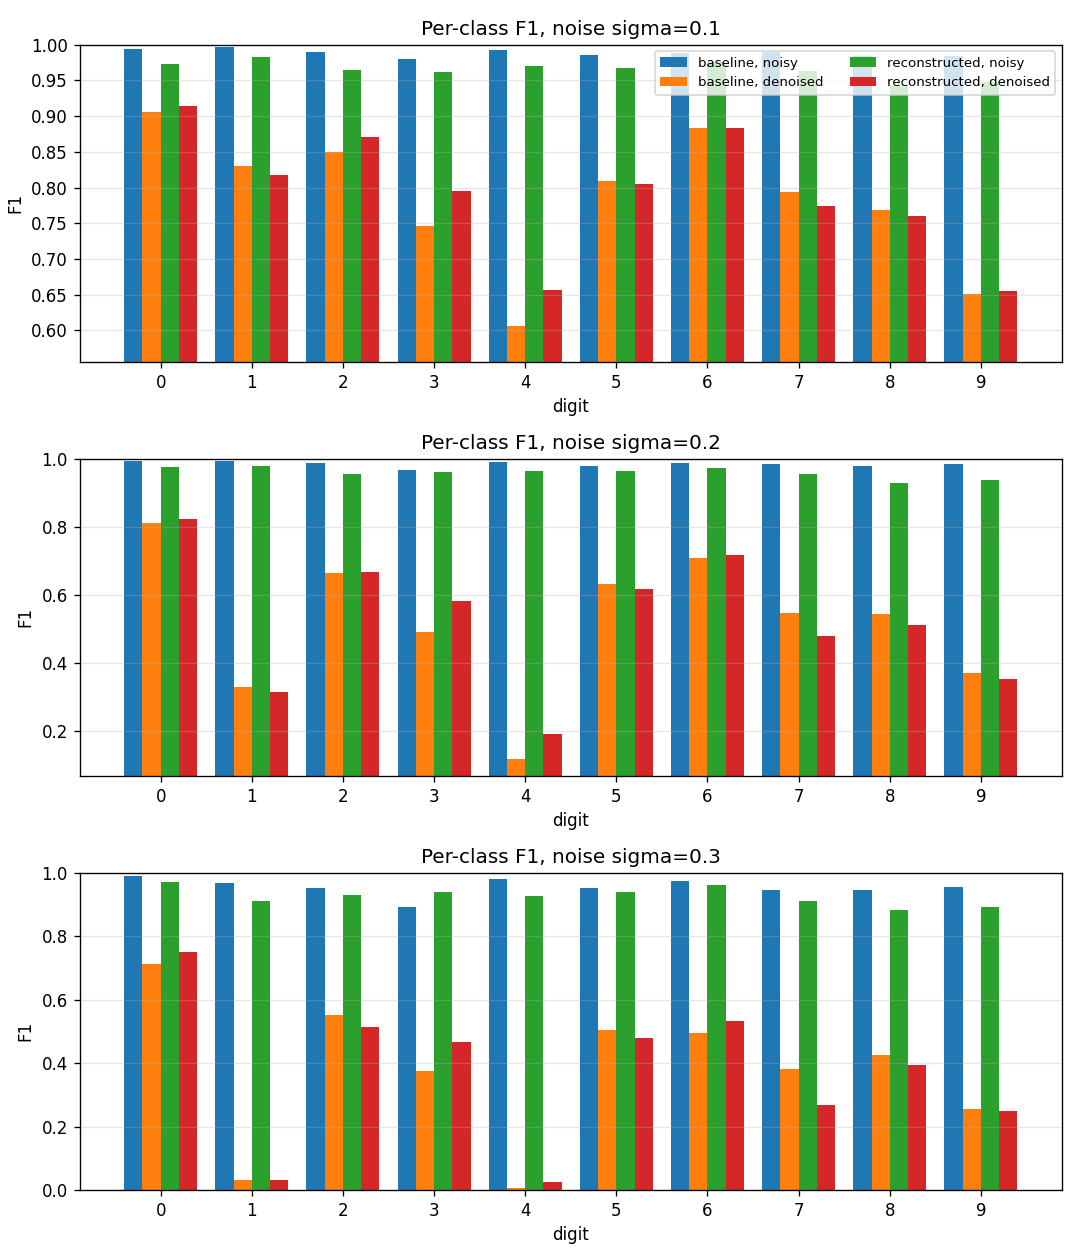

In [7]:
display(Image('results/part3_denoising.png'))
df = pd.DataFrame([{k: (v if k == 'sigma' else v['macro_f1']) for k, v in r.items()} for r in results['part3']]).set_index('sigma')
df.columns = pd.MultiIndex.from_tuples([tuple(c.split('_')) for c in df.columns], names=['classifier', 'input'])
display(df.round(4))
display(Image('results/part3_macro_f1.png'))
display(Image('results/part3_f1_per_class.png'))

**Result: the VAE does not denoise, it hurts – and more so as σ grows.** The baseline CNN on raw noisy images barely degrades (macro F1 0.989 / 0.984 / 0.955 at σ = 0.1 / 0.2 / 0.3), while on VAE-denoised images it falls to 0.784 / 0.522 / 0.374 – the gap grows from 0.20 to 0.46 to 0.58. The reconstructed classifier shows the same pattern.
The denoised images look clean but are often the *wrong digit* - which is the reason.

Why:
1. **Clipped noise is not neutral.** The background is 0, so negative noise there is clipped away and only positive noise stays – the background gets brighter by ≈ 0.4·σ per pixel on average, over ~600 background pixels. The image looks "brighter and fuller" than anything the encoder saw in training.
2. **The encoder never saw noisy images**, so this input lands μ in the wrong region of the latent space – bright, fat shapes look most like 8, 3, 0 (see the t-SNE below).
3. **The decoder then produces a clean, typical digit from the wrong region** – noise removed, signal destroyed with it.

Both classifiers score about the same on VAE output: the bottleneck is the VAE, not the classifier.
Per class (bar plots):
- **4 and 1 collapse**: 4 is already the worst at σ = 0.1 (F1 ≈ 0.61) and both are near 0 at σ = 0.3. The brightened background closes the open top of a 4 (→ 9) and puts "loops" around the single thin stroke of a 1 (→ 3/8/6) – the same moves as the `4 -> 9` and `1 -> 8` interpolations above.
- **0 holds up best** (≈ 0.71–0.75 at σ = 0.3), then 6: they are already big round shapes, so extra brightness hardly changes what they look like.
- F1 of a class also drops when *other* digits are wrongly predicted as it (lower precision), so a low bar does not always mean that class's own images failed.
A VAE trained on noisy inputs with clean targets would be the fix.

## Latent space – t-SNE of μ

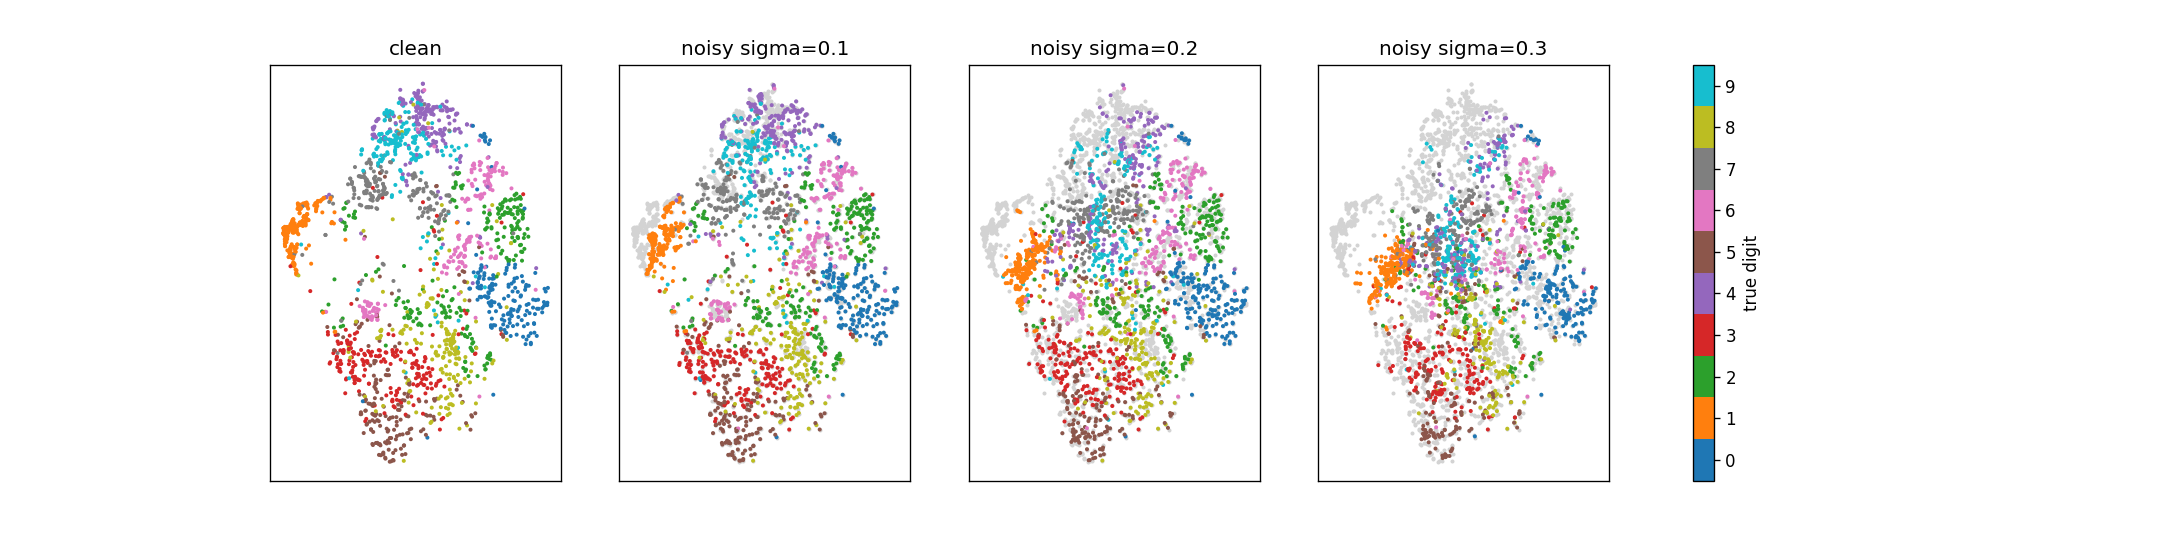

In [8]:
display(Image('results/latent_tsne.png'))

t-SNE squeezes the 16-dim μ into 2D while keeping neighbours close. Clean and noisy codes are embedded **together**, so all panels share one map.

- **Clean** – one cluster per digit, and neighbouring clusters are similar shapes: 4/9/7 at the top, 3/5/8 at the bottom, 1 alone on the left.
- **σ = 0.1** – almost the same layout, a few points start to leave their cluster.
- **σ = 0.2 / 0.3** – codes leave their clusters and pile up in the middle of the map, where 4, 7, 9, 2 and 8 get mixed together – the decoder turns that region into the ambiguous blurry digits seen above.
  The 1s stay together but move out of the clean "1" region (the grey area on the left empties), so they are decoded as something else – matching F1 ≈ 0 for digit 1. The 0s mostly stay in place, matching 0's best F1.

This drift is why VAE-denoising fails: noise moves μ to the wrong region, and the decoder faithfully decodes that wrong region.